In [1]:
### NB: Much of what is included below draws on examples from the "NLTK Book" (https://www.nltk.org/book/ch01.html) Steven Bird, Ewan Klein, and Edward Loper. Highly recommended to continue with the kinds of work introduced in the workshop. 

In [2]:
## Imports

from cltkreaders.lat import LatinTesseraeCorpusReader
from pprint import pprint
from natsort import natsorted
from latintools import preprocess

In [3]:
# Setup corpus

T = LatinTesseraeCorpusReader()

In [4]:
# Sample text

aeneid = natsorted([file for file in T.fileids() if 'aeneid' in file])
aeneid_text = "\n".join([next(T.texts(file, preprocess=preprocess)) for file in aeneid])

In [5]:
print('Beginning of Aeneid...')
print(aeneid_text[:100])

print()

print('End of Aeneid...')
print(aeneid_text[-100:])

Beginning of Aeneid...
arma uirumque cano troiae qui primus ab oris
italiam fato profugus lauiniaque uenit
litora multum il

End of Aeneid...
tore condit
feruidus ast illi soluuntur frigore membra
uitaque cum gemitu fugit indignata sub umbras


In [6]:
# Make a Text object with NLTK

from nltk import Text
aeneid_tokens = aeneid_text.split()
aeneid_Text = Text(aeneid_tokens)
print(aeneid_Text)

<Text: arma uirumque cano troiae qui primus ab oris...>


In [7]:
# Check type of Text object

type(aeneid_Text)

nltk.text.Text

In [8]:
# Check methods of Text object

pprint(dir(aeneid_Text))

['_CONTEXT_RE',
 '_COPY_TOKENS',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_context',
 '_train_default_ngram_lm',
 'collocation_list',
 'collocations',
 'common_contexts',
 'concordance',
 'concordance_list',
 'count',
 'dispersion_plot',
 'findall',
 'generate',
 'index',
 'name',
 'plot',
 'readability',
 'similar',
 'tokens',
 'vocab']


In [9]:
# Check methods of Text object, again

pprint([item for item in dir(aeneid_Text) if not item.startswith('_')])

['collocation_list',
 'collocations',
 'common_contexts',
 'concordance',
 'concordance_list',
 'count',
 'dispersion_plot',
 'findall',
 'generate',
 'index',
 'name',
 'plot',
 'readability',
 'similar',
 'tokens',
 'vocab']


In [10]:
# Make a KWIC list

concordance = aeneid_Text.concordance('aeneas', width=50, lines=5)
concordance

Displaying 5 of 153 matches:
cora morsu huc septem aeneas collectis nauibus omn
mmis et frangere saxo aeneas scopulum interea cons
ocatos praecipue pius aeneas nunc acris oronti nun
mine terres quid meus aeneas in te committere tant
mque benignam at pius aeneas per noctem plurima uo


In [11]:
# Get collocations

collocations = aeneid_Text.collocation_list(num=10)

for collocation in collocations:
    print(' '.join(collocation))

tum uero
pius aeneas
neque enim
nate dea
talia fatur
pater anchises
pater aeneas
per auras
ubi dicta
sic ait


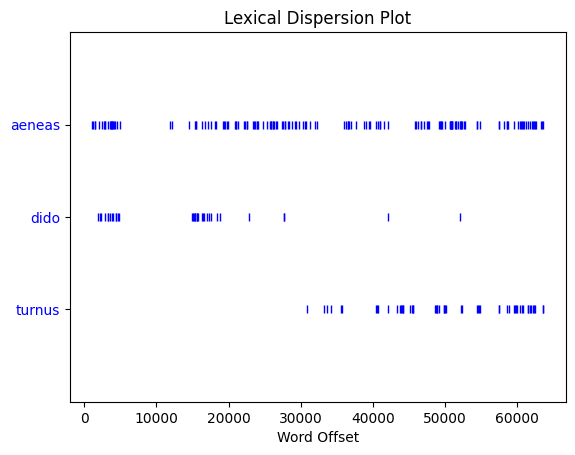

In [12]:
# Make a dispersion plot

displot = aeneid_Text.dispersion_plot(['aeneas', 'dido', 'turnus'])

In [13]:
# Get tokenized sents

tokenized_sents = T.tokenized_sents(aeneid)
sample = next(tokenized_sents)
print(sample[:5])

[('Arma', 'Arma', 'PROPN'), ('virum', 'uir', 'NOUN'), ('que', 'que', 'CCONJ'), ('cano', 'canus', 'ADJ'), (',', ',', 'PUNCT')]


In [14]:
# Get list of lemmas

tokenized_sents = T.tokenized_sents(aeneid)

all_lemmas = []
for sent in tokenized_sents:
    for token in sent:
        if token[1]:
            lemma = preprocess(token[1])
            if lemma:
                all_lemmas.append(preprocess(token[1], remove_spaces=True))
        

In [15]:
# Make lemmatized Text object

aeneid_lemmatized_Text = Text(all_lemmas)

In [16]:
print(aeneid_lemmatized_Text)

<Text: arma uir que canus troia qui primus ab...>


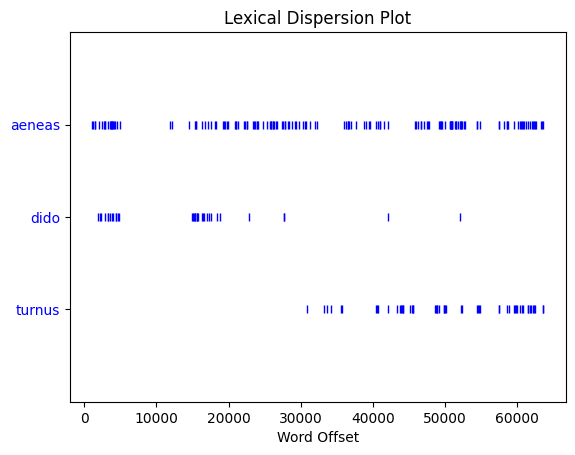

In [17]:
# Before, unlemmatized

displot = aeneid_Text.dispersion_plot(['aeneas', 'dido', 'turnus'])

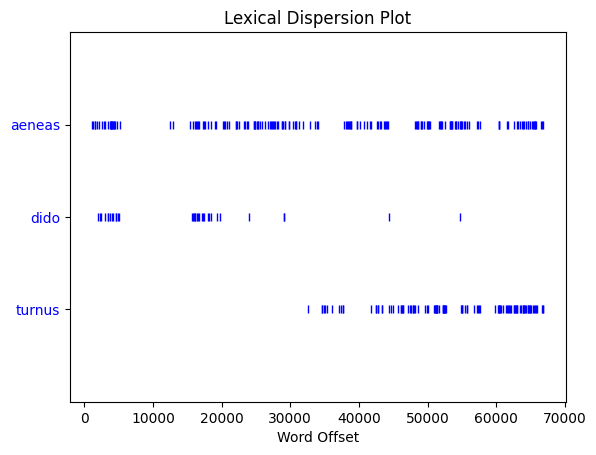

In [18]:
# After, lemmatized

displot = aeneid_lemmatized_Text.dispersion_plot(['aeneas', 'dido', 'turnus'])

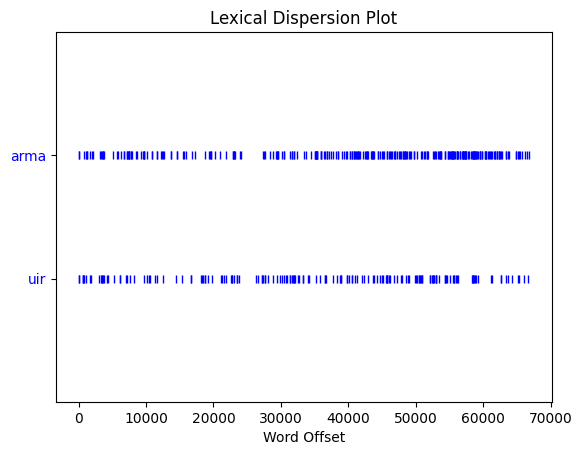

In [19]:
# Other ideas

displot = aeneid_lemmatized_Text.dispersion_plot(['arma', 'uir'])

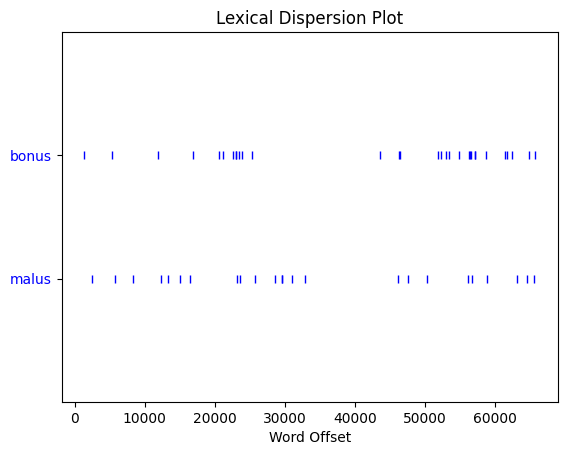

In [20]:
# Other ideas

displot = aeneid_lemmatized_Text.dispersion_plot(['bonus', 'malus'])

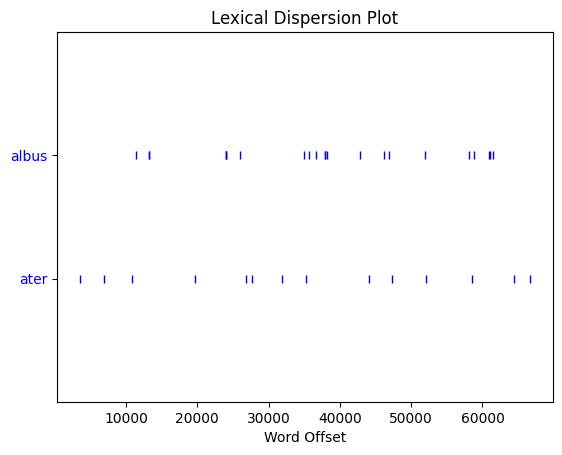

In [21]:
# Other ideas

displot = aeneid_lemmatized_Text.dispersion_plot(['albus', 'ater'])

In [22]:
# Find similar words

similars = aeneid_lemmatized_Text.similar('aeneas', num=10)

et uir que urbs genus atque roma sum hic si


In [23]:
# Find similar words

similars = aeneid_lemmatized_Text.similar('pater', num=10)

deus uir rex do caput uolo manus pius latinus sum


In [24]:
# Get frequencies

from collections import Counter
counts = Counter(aeneid_lemmatized_Text)
print(counts.most_common(15))

[('que', 3096), ('et', 2158), ('qui', 1102), ('hic', 843), ('in', 772), ('sum', 522), ('atque', 412), ('tu', 404), ('ego', 353), ('per', 351), ('ille', 347), ('omnis', 329), ('ad', 321), ('ipse', 283), ('do', 282)]


In [25]:
# Make "stops"

stops = [k for k, v in counts.most_common(10)]
print(stops)

['que', 'et', 'qui', 'hic', 'in', 'sum', 'atque', 'tu', 'ego', 'per']


In [26]:
# Remove stops

stopped_lemmas = [lemma for lemma in all_lemmas if lemma not in stops]
aeneid_lemmatized_stopped_Text = Text(stopped_lemmas)

In [27]:
similars = aeneid_lemmatized_stopped_Text.similar('pater', num=10)

rex manus pius uero uir primus iuno gens populus ad


In [28]:
# Generate text ?!?!

print(aeneid_Text.generate(text_seed='aeneas est'.split()))

Building ngram index...


aeneas est nunc iter ad regem nobis murosque latinos arma parate animis et spe
iam praecipit hostem qualis ubi hibernam lyciam xanthique fluenta
deserit ac delum maternam inuisit apollo instauratque choros mixtique
altaria circum populeis adsunt euincti tempora taenis cum saeuo e
scopulo multa uix arte reuolsus amissis remis atque ordine debilis uno
inrisam sine honore ratem sergestus agebat qualis saepe uiae deprensus
in aggere serpens aerea quem obliquum rota transiit aut grauis ictu
seminecem liquit saxo lacerumque uiator nequiquam longos fugiens dat
corpore tortus parte ferox ardensque oculis et corpore inhaeret
tantane me tenuit uiuendi nate uoluptas ut pro me tantum
aeneas est nunc iter ad regem nobis murosque latinos arma parate animis et spe
iam praecipit hostem qualis ubi hibernam lyciam xanthique fluenta
deserit ac delum maternam inuisit apollo instauratque choros mixtique
altaria circum populeis adsunt euincti tempora taenis cum saeuo e
scopulo multa uix arte reuolsus amissi

In [29]:
# Get frequencies; similar to counter

from nltk import FreqDist
freqs = FreqDist(aeneid_lemmatized_Text)

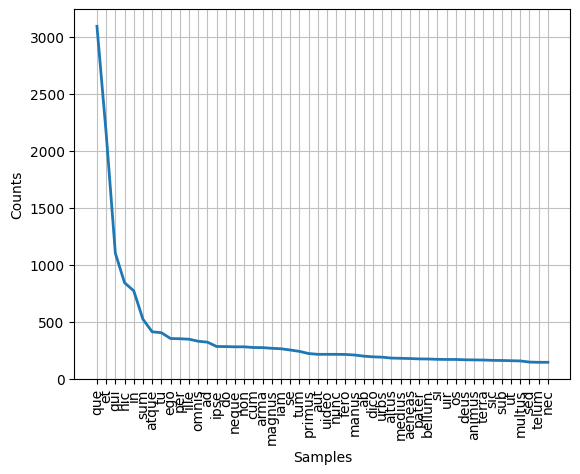

In [30]:
# Plot freqs

freqs.plot(50, cumulative=False);

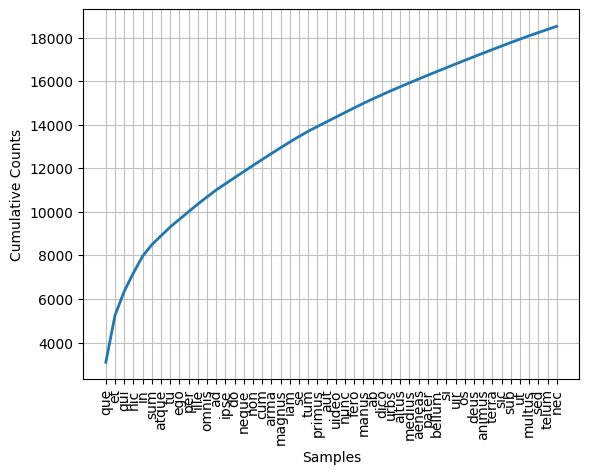

In [31]:
# Plot freqs, cumulative

freqs.plot(50, cumulative=True);

In [32]:
# Length of Text

len(aeneid_lemmatized_Text)

66925